<a href="https://colab.research.google.com/github/sana-sadiq-astro/transit-timing-pipeline/blob/main/Transit_timing_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Measuring orbital period change of WASP-18 b and WASP-12 b from TESS data

**Author:** Sana Sadiq

**Goal:** Measure the mid-time of every transit of two hot Jupiters, build an O-C (observed minus calculated) diagram, and test whether their orbital periods are changing.

**Data:** NASA TESS, SPOC 2-minute cadence, accessed with the Lightkurve package. WASP-18 b: 10 sectors (2, 3, 29, 30, 69, 96, 103, 104, 105, 106). WASP-12 b: 6 sectors (20, 43, 44, 45, 71, 72).

**Method:** (1) download each sector, (2) find the period and transit time with BLS, (3) flatten the light curve while protecting the transits, (4) remove bad transits, (5) fit the transit shape, (6) fit the mid-time of each transit, (7) fit a straight line and a curve to the mid-times and compare them.

In [ ]:
!pip install lightkurve batman-package -q
import numpy as np, matplotlib.pyplot as plt
import lightkurve as lk, batman
from scipy.signal import savgol_filter
from scipy.optimize import least_squares

def arr(x):
    if hasattr(x, "filled"):
        x = x.filled(np.nan)
    return np.array(getattr(x, "value", x), dtype=float)

def mad_sigma(v):
    return 1.4826 * np.median(np.abs(v - np.median(v)))

def transit_model(theta, t, P, u):
    t0, rp, a, inc = theta
    p = batman.TransitParams()
    p.t0, p.per, p.rp, p.a, p.inc = t0, P, rp, a, inc
    p.ecc, p.w = 0.0, 90.0
    p.u, p.limb_dark = list(u), "quadratic"
    return batman.TransitModel(p, t, supersample_factor=3,
                               exp_time=2/1440).light_curve(p)

def get_sectors(name, wanted=None):
    res = lk.search_lightcurve(name, mission="TESS",
                               author="SPOC", exptime=120)
    out = {}
    for i, m in enumerate(res.table["mission"]):
        s = int(str(m).split()[-1])
        if wanted is None or s in wanted:
            out[s] = res[i].download()
    return out

def first_pass(lc, Pg, dur):
    f = lc.remove_nans().normalize().flatten(window_length=1001)
    b = f.to_periodogram("bls", period=np.linspace(Pg*0.99, Pg*1.01, 2000),
                         duration=[0.8*dur, dur, 1.1*dur])
    return (float(b.period_at_max_power.value),
            float(b.transit_time_at_max_power.value))

def clean(lc, P, t0, dur, win=721):
    t = np.array(lc.time.value, dtype=float)
    f = arr(lc.flux)
    ok = np.isfinite(t) & np.isfinite(f)
    t, f = t[ok], f[ok]
    f = f / np.median(f)
    ph = ((t - t0 + 0.5*P) % P) - 0.5*P
    intr = np.abs(ph) < 0.75*dur
    trend = np.ones_like(f)
    cuts = np.where(np.diff(t) > 0.5)[0] + 1
    for seg in np.split(np.arange(len(t)), cuts):
        out = ~intr[seg]
        w = min(win, int(out.sum()))
        if w % 2 == 0:
            w -= 1
        if w < 5:
            continue
        sm = savgol_filter(f[seg][out], w, 2)
        trend[seg] = np.interp(t[seg], t[seg][out], sm)
    fl = f / trend
    med = np.median(fl)
    keep = fl < med + 4*mad_sigma(fl)
    return t[keep], fl[keep]

def find_bad(t, fl, P, T, dur):
    ph = ((t - T + 0.5*P) % P) - 0.5*P
    ep = np.round((t - T) / P).astype(int)
    sig = mad_sigma(fl[np.abs(ph) > 0.8*dur])
    inn = np.abs(ph) < 0.02
    lv = {}
    for e in np.unique(ep[inn]):
        m = inn & (ep == e)
        lv[int(e)] = (float(np.median(fl[m])), int(m.sum()))
    typ = np.median([v[0] for v in lv.values()])
    thr = max(0.001, 6*sig/np.sqrt(29))
    bad = [e for e, (l, n) in lv.items() if n < 20 or abs(l - typ) > thr]
    return bad, len(lv)

def fit_shape(t, fl, P, T, dur, u):
    ph = ((t - T + 0.5*P) % P) - 0.5*P
    w = np.abs(ph) < max(0.2, 2*dur)
    tw, fw, pw = t[w], fl[w], ph[w]
    sig = mad_sigma(fw[np.abs(pw) > 0.8*dur])
    rp0 = np.sqrt(max(1 - np.median(fw[np.abs(pw) < 0.02]), 1e-4))
    a0 = float(np.clip(P/(np.pi*dur), 1.6, 7.9))
    r = least_squares(lambda th: (fw - transit_model(th, tw, P, u)) / sig,
                      x0=[T, rp0, a0, 84.0],
                      bounds=([T-0.05, 0.5*rp0, 1.5, 70.0],
                              [T+0.05, 1.6*rp0, 8.0, 90.0]))
    return r.x, 2*r.cost/(w.sum() - 4)

def time_transits(t, fl, Pref, T, shape, dur, u, win):
    ph = ((t - T + 0.5*Pref) % Pref) - 0.5*Pref
    sig = mad_sigma(fl[np.abs(ph) > 0.8*dur])
    ep = np.round((t - T) / Pref).astype(int)
    out = []
    for e in np.unique(ep):
        tp = T + e*Pref
        m = np.abs(t - tp) < win
        if m.sum() < 0.83*(2*win/(2/1440)):
            continue
        tm, fm = t[m], fl[m]
        r = least_squares(
            lambda x: (fm - transit_model([x[0], *shape], tm, Pref, u)) / sig,
            x0=[tp], bounds=([tp-0.03], [tp+0.03]))
        out.append((e, r.x[0], 1/np.sqrt((r.jac**2).sum())))
    return out

def wfit(E, y, er, deg):
    A = np.vander(E, deg + 1, increasing=True)
    W = 1 / er**2
    cov = np.linalg.inv(A.T @ (A * W[:, None]))
    beta = cov @ (A.T @ (W * y))
    return beta, cov, np.sum(W * (y - A @ beta)**2)

In [ ]:
def analyze(name, P_ref, dur, sectors=None, u=(0.25, 0.30)):
    raw = get_sectors(name, sectors)
    secs = sorted(raw)
    win = max(0.15, 1.5*dur)
    data, P0, T0, fits = {}, {}, {}, {}
    n_all = n_bad = 0
    for s in secs:
        P0[s], T0[s] = first_pass(raw[s], P_ref, dur)
        t, fl = clean(raw[s], P0[s], T0[s], dur)
        bad, nt = find_bad(t, fl, P0[s], T0[s], dur)
        ep = np.round((t - T0[s]) / P0[s]).astype(int)
        keep = ~np.isin(ep, bad)
        data[s] = (t[keep], fl[keep])
        n_all += nt; n_bad += len(bad)
        fits[s] = fit_shape(*data[s], P0[s], T0[s], dur, u)
        print("sector", s, "Rp/Rs %.4f chi2 %.2f excluded %s"
              % (fits[s][0][1], fits[s][1], bad))
    shape = tuple(np.median([fits[s][0][1:] for s in secs], axis=0))
    print("median shape (Rp/Rs, a/Rs, inc):", np.round(shape, 4))

    rows = []
    for s in secs:
        for e, tc_, er_ in time_transits(*data[s], P_ref, T0[s],
                                         shape, dur, u, win):
            rows.append((s, e, tc_, er_))
    rows = np.array(rows)
    np.savetxt(name.replace(" ", "") + "_times.csv", rows, delimiter=",",
               header="sector,epoch_in_sector,mid_time_BTJD,error_d")

    tc, er0, sec = rows[:, 2], rows[:, 3], rows[:, 0]
    T_ref = float(tc[0])
    E = np.round((tc - T_ref) / P_ref).astype(int)
    y = tc - T_ref
    n = len(E)
    b1, c1, x1 = wfit(E, y, er0, 1)
    k = max(1.0, np.sqrt(x1 / (n - 2)))
    er = er0 * k
    b1, c1, x1 = wfit(E, y, er, 1)
    b2, c2, x2 = wfit(E, y, er, 2)
    f = 365.25 * 86400e3 / b1[1]
    dPdt, dPdt_e = 2*b2[2]*f, 2*np.sqrt(c2[2, 2])*f
    bic1, bic2 = x1 + 2*np.log(n), x2 + 3*np.log(n)
    print("transits used %d (excluded %d of %d)" % (n, n_bad, n_all))
    print("error scale %.2f | P = %.8f +/- %.8f d"
          % (k, b1[1], np.sqrt(c1[1, 1])))
    print("chi2/dof %.2f | BIC line %.1f, curve %.1f"
          % (x1/(n-2), bic1, bic2))
    print("dP/dt = %.1f +/- %.1f ms/yr" % (dPdt, dPdt_e))

    oc = (y - (b1[0] + b1[1]*E)) * 86400
    Eg = np.linspace(E.min(), E.max(), 300)
    plt.figure(figsize=(9, 4))
    for s in secs:
        m = sec == s
        plt.errorbar(E[m], oc[m], er[m]*86400, fmt=".", label=f"S{s}")
    plt.plot(Eg, (b2[0] + b2[1]*Eg + b2[2]*Eg**2
                  - (b1[0] + b1[1]*Eg)) * 86400, "k")
    plt.axhline(0, c="gray", lw=0.5)
    plt.xlabel("orbit number"); plt.ylabel("O - C (s)")
    plt.title(name); plt.legend(ncol=5, fontsize=7); plt.show()
    return dict(rows=rows, P=b1[1], dPdt=dPdt, dPdt_err=dPdt_e,
                shape=shape, bic=(bic1, bic2))

## Code
The cell below installs the packages and defines the functions. Each function does one step of the method above.

## WASP-18 b
Running the full analysis on all 10 sectors. The plot shows O-C (in seconds) against orbit number. The black curve is the quadratic fit.

sector 2 Rp/Rs 0.0990 chi2 1.11 excluded []
sector 3 Rp/Rs 0.0986 chi2 1.18 excluded []
sector 29 Rp/Rs 0.0994 chi2 1.07 excluded []
sector 30 Rp/Rs 0.0992 chi2 1.31 excluded [12, 15]
sector 69 Rp/Rs 0.0997 chi2 1.25 excluded [6]
sector 96 Rp/Rs 0.0996 chi2 1.28 excluded []
sector 103 Rp/Rs 0.0992 chi2 1.29 excluded [13, 18]
sector 104 Rp/Rs 0.0991 chi2 1.13 excluded []
sector 105 Rp/Rs 0.1007 chi2 1.45 excluded [19, 27]
sector 106 Rp/Rs 0.0985 chi2 1.20 excluded [-1]
median shape (Rp/Rs, a/Rs, inc): [ 0.0992  3.3897 83.1005]
transits used 213 (excluded 8 of 226)
error scale 1.07 | P = 0.94145236 +/- 0.00000001 d
chi2/dof 1.00 | BIC line 221.7, curve 221.7
dP/dt = -2.5 +/- 1.1 ms/yr


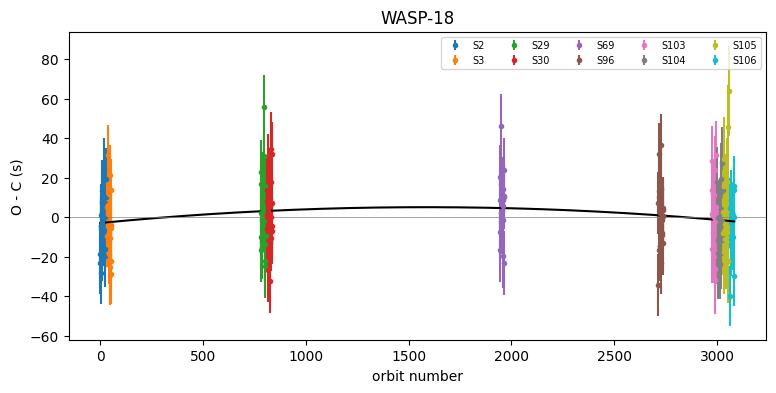

In [ ]:
w18 = analyze("WASP-18", P_ref=0.941452, dur=0.09)

## WASP-12 b
The same analysis on 6 sectors.

sector 20 Rp/Rs 0.1162 chi2 1.01 excluded []
sector 43 Rp/Rs 0.1167 chi2 1.05 excluded []
sector 44 Rp/Rs 0.1159 chi2 1.04 excluded []
sector 45 Rp/Rs 0.1150 chi2 1.02 excluded []
sector 71 Rp/Rs 0.1161 chi2 0.98 excluded []
sector 72 Rp/Rs 0.1190 chi2 1.36 excluded []
median shape (Rp/Rs, a/Rs, inc): [ 0.1161  2.9872 82.7632]
transits used 118 (excluded 0 of 121)
error scale 1.04 | P = 1.09141658 +/- 0.00000011 d
chi2/dof 1.00 | BIC line 125.5, curve 127.9
dP/dt = -21.6 +/- 13.8 ms/yr


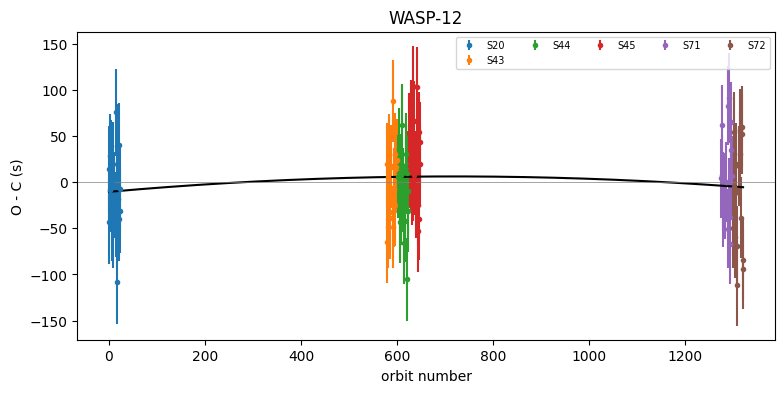

In [ ]:
w12 = analyze("WASP-12", P_ref=1.091419, dur=0.125, u=(0.30, 0.30))

## Injection test
I add a known period change (0, -3, -6, -12, -29 ms/yr) to the WASP-18 b timings and check what the fit recovery overs.

In [ ]:
rows = w18["rows"]
tc, er0 = rows[:, 2], rows[:, 3]
P = 0.941452
E = np.round((tc - tc[0]) / P).astype(int)
for inj in (0, -3, -6, -12, -29):
    dPdN = inj * 1e-3 / 86400 * P / 365.25
    y = tc + 0.5 * dPdN * E**2 - tc[0]
    b1, c1, x1 = wfit(E, y, er0, 1)
    b2, c2, x2 = wfit(E, y, er0, 2)
    f = 365.25 * 86400e3 / b1[1]
    print(inj, "-> recovered %.1f +/- %.1f ms/yr"
          % (2*b2[2]*f, 2*np.sqrt(c2[2, 2])*f))

0 -> recovered -2.5 +/- 1.0 ms/yr
-3 -> recovered -5.5 +/- 1.0 ms/yr
-6 -> recovered -8.5 +/- 1.0 ms/yr
-12 -> recovered -14.5 +/- 1.0 ms/yr
-29 -> recovered -31.5 +/- 1.0 ms/yr


## Results

| | WASP-18 b | WASP-12 b |
|---|---|---|
| TESS sectors | 10 | 6 |
| Transits used | 213 (13 of 226 excluded) | 118 |
| Median Rp/Rs | 0.0992 | 0.1161 |
| BIC (line / curve) | 221.7 / 221.7 | 125.5 / 127.9 |
| dP/dt | -2.5 ± 1.1 ms/yr | -21.6 ± 13.8 ms/yr |

**Injection test:** injected 0, -3, -6, -12, -29 ms/yr gave recovered -2.5, -5.5, -8.5, -14.5, -31.5 ms/yr (each ± 1.0). The constant offset of about -2.5 ms/yr is the baseline of the method.

**WASP-18 b:** No significant shrinking in orbit was detected.
**WASP-12 b:** It is already known to have shrinking orbit,my result has matching signs but with only 1.6 sigma from 0.

## Limitations
- Only TESS data were used.
- Limb-darkening coefficients are fixed.
- The period change is modelled with a simple quadratic.
- The WASP-12 b result is not significant with this data set alone.

## What I learned
**O-C diagram:** O is observed mid time transit and C is calculated time. For O-C, if period is constant the points scatter around zero and in flat line. If period is shrinking, the points scatter and bend in downward curve over years.

**What dP/dt means:** dP/dt is how much the orbital period changes each year, in milliseconds per year. A negative value means the period is getting shorter, so the orbit is shrinking and the planet is orbiting slightly faster. I got -2.5 ± 1.1 ms/yr.

**The injection test:** The injection test adds a fake orbital shrinking of a known size to a real transit times.In my injection test, zero injected decay still gave -2.5, so this is my method's baseline, and the BIC for the line and the curve were equal, so there is no significant shrinking. A very small decay cannot be ruled out with about 8 years of data.

**Why I fit each transit separately:** Each transit is fitted on its own to get its own mid-time, which gives the points of the O-C diagram. If I fitted all of them together, I would be assuming a constant period and couldn't test whether it changes. It also shows me bad transits or sectors that disagree with the rest.